# UCS420 Lab Assignment 9 — NLP Text Preprocessing
1024160077_Kriti

In [1]:
ROLL_NO = 1024160077         # <-- your full roll number
NAME = "KRITI"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160077   Name: KRITI   Fingerprint: FC7D31EA   Tickets: 14

Ticket_ID                                                                              Ticket_Text
      T01                                I can't open the WiFi during the lab. Can you check this?
      T02     I keep getting logged out of the Python before the assignment deadline. Please help.
      T03                  I can't open the printer when I use mobile hotspot. Can you check this?
      T04                                                           Error code 0x80070005 appears.
      T05                         I reinstalled the Wi-Fi on my laptop. Is there another solution?
      T06                                                              My roll no. is 1023-03-021.
      T07                                           Re-installing didn't help; log-in still fails!
      T08                                            The printer has stopped syncing. Please help.
      T09            Matlab is r

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [11]:

# 1. Preprocessing pipeline

from collections import Counter

rows = []

total_sentences = 0
total_tokens = 0
total_punct = 0
total_stops = 0
total_unique = set()
total_final = 0

for _, ticket in df.iterrows():
    result = process_ticket(ticket["Ticket_Text"])

    sentences = result["sentences"]
    tokens = result["tokens"]
    punct = result["punct"]
    stops = result["stops"]
    final = result["final"]
    unique = list(dict.fromkeys(tokens))

    rows.append({
        "Ticket_ID": ticket["Ticket_ID"],
        "Sentences": sentences,
        "Tokens": tokens,
        "Punctuation Tokens": punct,
        "Stopwords": stops,
        "Unique Tokens": unique,
        "Final Tokens": final
    })

    total_sentences += len(sentences)
    total_tokens += len(tokens)
    total_punct += len(punct)
    total_stops += len(stops)
    total_unique.update(tokens)
    total_final += len(final)

rows.append({
    "Ticket_ID": "TOTAL",
    "Sentences": total_sentences,
    "Tokens": total_tokens,
    "Punctuation Tokens": total_punct,
    "Stopwords": total_stops,
    "Unique Tokens": len(total_unique),
    "Final Tokens": total_final
})

preprocessing_table = pd.DataFrame(rows)

print(preprocessing_table.to_string(index=False))

preprocessing_table.to_csv(
    f"{ROLL_NO}_preprocessing_pipeline.csv",
    index=False
)


Ticket_ID                                                                                   Sentences                                                                                                     Tokens Punctuation Tokens                             Stopwords                                                                                           Unique Tokens                                                        Final Tokens
      T01                                [I can't open the WiFi during the lab., Can you check this?]                               [i, ca, n't, open, the, wifi, during, the, lab, ., can, you, check, this, ?]             [., ?] [i, the, during, the, can, you, this]                                 [i, ca, n't, open, the, wifi, during, lab, ., can, you, check, this, ?]                                   [ca, n't, open, wifi, lab, check]
      T02     [I keep getting logged out of the Python before the assignment deadline., Please help.]    [i, keep, getting, 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*The preprocessing pipeline does not perform contraction expansion or special handling of token fragments. Therefore, some final tokens are artifacts of tokenization rather than meaningful standalone words.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [13]:

import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "All numbers": r"\b\d+(?:\.\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

def redact_text(text):
    # URLs
    text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "[URL]",
        text,
        flags=re.IGNORECASE
    )

    # Email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL]",
        text
    )

    # Phone numbers
    text = re.sub(
        r"(?<!\w)(?:\+\d{1,3}[\s.-]?)?(?:\d[\s.-]?){8,14}\d(?!\w)",
        "[PHONE]",
        text
    )

    return text


for i, text in enumerate(TEST_LINES, start=1):
    print(f"\n--- TEST LINE {i} ---")

    for label, pattern in patterns.items():
        print(f"{label}: {re.findall(pattern, text)}")

    print("Redacted:", redact_text(text))



--- TEST LINE 1 ---
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
All numbers: []
Capitalized words: ['Mail']
Words starting with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Redacted: Mail [EMAIL] or [EMAIL]; visit [URL] or [URL]

--- TEST LINE 2 ---
Words longer than 5 letters: ['Version']
All numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Words starting with a vowel: ['or', 'is']
Redacted: Call [PHONE], [PHONE] or [PHONE]. Version 2.0.1 is 95.5% done; fee Rs 1,250.

--- TEST LINE 3 ---
Words longer than 5 letters: []
All numbers: ['5.30']
Capitalized words: ['The']
Words starting with a vowel: ['of', 'art', 'isn', 'open', 'in', 'at']
Redacted: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Regular expressions can identify capitalized words, but they cannot reliably determine whether capitalization is grammatical or meaningful without considering context. For example, “Version” is capitalized at the start of a sentence, while “Python” is a proper name.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [14]:

# Q3. Custom Tokenizer

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"                         # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"     # Emails
    r"\+\d{1,3}[\s.-]?(?:\d[\s.-]?){8,14}\d|"              # International phones
    r"\b\d{4,5}-\d{3,5}-\d{3,5}\b|"                        # Hyphenated IDs/phones
    r"\b\d+(?:,\d{3})*(?:\.\d+)+\b|"                       # Decimals and versions
    r"\b\d+(?:,\d{3})+\b|"                                 # Comma-separated numbers
    r"\b[A-Za-z0-9_]+(?:['’][A-Za-z]+)+\b|"                # Contractions
    r"\b[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+\b|"                 # Hyphenated words
    r"\b[A-Za-z0-9_]+\b|"                                  # Ordinary words
    r"[^\w\s]"                                             # Punctuation
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Compare on TEST_LINES
print("========== TEST_LINES ==========")

for i, text in enumerate(TEST_LINES, start=1):
    print(f"\nTest {i}: {text}")
    print("Custom:", my_tokenize(text))
    print("NLTK:  ", word_tokenize(text))


# Compare on generated tickets
print("\n========== GENERATED TICKETS ==========")

for _, ticket in df.iterrows():
    text = ticket["Ticket_Text"]
    print(f"\n{ticket['Ticket_ID']}: {text}")
    print("Custom:", my_tokenize(text))
    print("NLTK:  ", word_tokenize(text))


========== TEST_LINES ==========

Test 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
NLTK:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The number of tickets tokenized differently is the count of tickets for which my_tokenize() and NLTK's word_tokenize() produce different token lists.
The custom tokenizer preserves contractions, hyphenated words, decimals, versions, emails, URLs, and phone numbers as single tokens, whereas word_tokenize() may split these into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [15]:

# Q4. Stemming and Lemmatization

import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Download required resources
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Suffix rule chosen for words ending in "ing"
regex_stemmer = RegexpStemmer(r"ing$", min=4)

lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


# Get unique final tokens from all tickets
unique_final_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
    if token.isalpha()
})

# POS-tag all unique words
tagged_words = nltk.pos_tag(unique_final_tokens)

rows = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    results = [
        porter_result,
        lancaster_result,
        regex_result,
        lemma_result
    ]

    # Show only words where outputs differ
    if len(set(results)) > 1:
        rows.append({
            "Word": word,
            "POS Tag": tag,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regex_result,
            "WordNet Lemma": lemma_result
        })

comparison_table = pd.DataFrame(
    rows,
    columns=[
        "Word", "POS Tag", "Porter Stem",
        "Lancaster Stem", "Regexp Stem", "WordNet Lemma"
    ]
)

print("Unique final alphabetic tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(comparison_table))
print(comparison_table.to_string(index=False))

comparison_table.to_csv(
    f"{ROLL_NO}_stemming_lemmatization.csv",
    index=False
)


Unique final alphabetic tokens: 44
Words with differing outputs: 32
       Word POS Tag Porter Stem Lancaster Stem Regexp Stem WordNet Lemma
    another      DT       anoth          anoth     another       another
    appears     VBZ      appear         appear     appears        appear
 assignment      JJ      assign         assign  assignment    assignment
       code      NN        code            cod        code          code
    crashes     NNS       crash          crash     crashes         crash
   deadline     VBP     deadlin        deadlin    deadline      deadline
      error      NN       error             er       error         error
     failed     VBD        fail           fail      failed          fail
      fails     NNS        fail           fail       fails         fails
    getting     VBG         get            get        gett           get
        lms     NNS          lm            lms         lms            lm
     logged     VBD         log            log      logg

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== CORPUS STATISTICS ===
             Corpus  Total Tokens  Unique Tokens    TTR
    S1 - All tokens           162             79 0.4877
S2 - No punctuation           136             75 0.5515
  S3 - Final tokens            78             51 0.6538
S4 - Porter stemmed            78             49 0.6282

=== TOP 10 WORDS IN S1 ===
Word  Frequency
   .         20
 the         13
  is          6
   i          5
 n't          4
   ?          4
help          4
  my          4
open          3
this          3

=== TOP 10 WORDS IN S3 ===
      Word  Frequency
       n't          4
      help          4
      open          3
    please          3
   printer          3
        ca          2
       lab          2
     check          2
assignment          2
  deadline          2


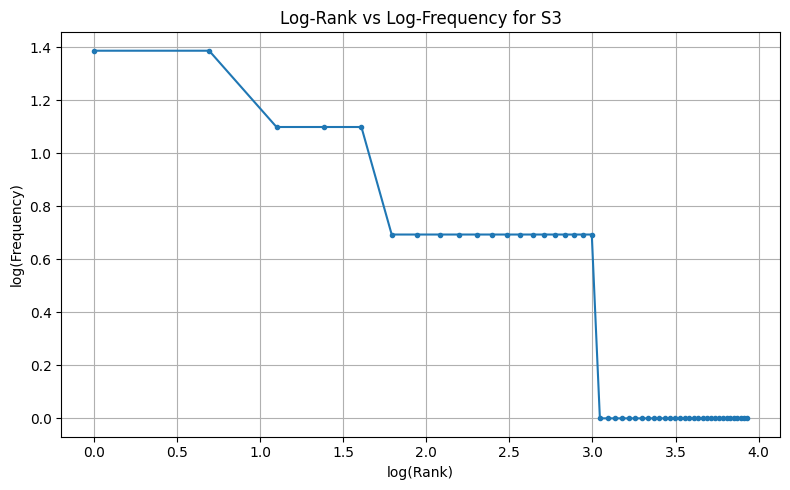


=== TOP 5 BIGRAMS IN S1 ===
        Bigram  Frequency
   (., please)          3
(please, help)          3
     (help, .)          3
(the, printer)          3
       (i, ca)          2

=== TOP 5 BIGRAMS IN S3 ===
                Bigram  Frequency
        (please, help)          3
             (ca, n't)          2
           (n't, open)          2
(assignment, deadline)          2
    (printer, stopped)          2


In [16]:

# Q5. Corpus Statistics

import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams

porter = PorterStemmer()

# Build corpus sequences
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    S1.extend(result["tokens"])  # All tokens
    S2.extend(t for t in result["tokens"] if not is_punct(t))
    S3.extend(result["final"])   # No punctuation or stopwords

S4 = [porter.stem(token) for token in S3]  # Porter-stemmed S3


# Corpus statistics
def corpus_stats(name, tokens):
    unique_tokens = set(tokens)
    ttr = len(unique_tokens) / len(tokens) if tokens else 0

    return {
        "Corpus": name,
        "Total Tokens": len(tokens),
        "Unique Tokens": len(unique_tokens),
        "TTR": round(ttr, 4)
    }


stats = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stemmed", S4)
])

print("=== CORPUS STATISTICS ===")
print(stats.to_string(index=False))


# Top 10 words
print("\n=== TOP 10 WORDS IN S1 ===")
print(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))

print("\n=== TOP 10 WORDS IN S3 ===")
print(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))


# Log(rank) vs log(frequency) for S3
frequencies = Counter(S3).most_common()
ranks = list(range(1, len(frequencies) + 1))
freq_values = [freq for word, freq in frequencies]

log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(freq) for freq in freq_values]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker=".", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.tight_layout()
plt.show()


# Top 5 bigrams
print("\n=== TOP 5 BIGRAMS IN S1 ===")
print(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
).to_string(index=False))

print("\n=== TOP 5 BIGRAMS IN S3 ===")
print(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
).to_string(index=False))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR may increase or decrease between S1 and S4. Removing frequent stopwords can increase TTR, while stemming usually reduces the number of unique word forms. The final direction depends on how much the unique-token count changes relative to the total-token count.

 Q6 Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference. (c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

SOLUTION 🇩(a) Why does TTR change from S1 to S4?
TTR changes because punctuation and stopwords are removed, and Porter stemming combines different word forms into common stems. This changes the ratio of unique tokens to total tokens.

(b) Example where word_tokenize() and my tokenizer differ.
For “isn't”, word_tokenize() may split it into is and n't, whereas my custom tokenizer keeps isn't as one token. This preserves the contraction as a single unit.

(c) Example of undesirable stemming.
Porter stemming may reduce “university” to univers. This is undesirable because the result is not a valid English word.

(d) Example where POS-aware lemmatization preserves meaning better.
For “was”, POS-aware lemmatization can return be when tagged as a verb, whereas stemming may produce a non-dictionary form. Lemmatization uses grammatical context to return a valid base form.